# Notebook 2 — a point mass navigating around one circular obstacle

Environment time `k`, internal Flow time `t`, and Actor optimizer count `N`
are different variables. The deployed policy uses one finite-chain ODE
sampler in TD backups, numerical policy evaluation, and environment tests;
AM matching uses the same frozen Base's finite-chain SDE as official QAM.
This experiment uses official QAM's TD/AM structure, but freezes a separately
pretrained behavior Flow and does not reproduce its full engineering stack.
Official agents/qam.py commit: 2726d767c9a0a7a46d49693f0391f73dc2cf58ac.

In [1]:
from __future__ import annotations

import copy
from dataclasses import dataclass, fields
import hashlib
import importlib.util
import json
import math
import os
from pathlib import Path
import secrets
import shutil
import sys
import time

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle
import numpy as np
import pandas as pd
from scipy.special import ndtri
from scipy.stats import qmc
import torch

ROOT = Path(__file__).resolve().parents[1] if '__file__' in globals() else Path.cwd()
CONFIG_PATH = ROOT/'configs/qam_point_obstacle.json'
CORE_PATH = ROOT/'notebooks/02_qam_td_terminal_error.py'
spec = importlib.util.spec_from_file_location('point_obstacle_lean_core', CORE_PATH)
core = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = core
spec.loader.exec_module(core)
torch.set_num_threads(min(4, torch.get_num_threads()))


@dataclass(frozen=True)
class Config:
    dimension: int = 2
    horizon: int = 28
    start_x: tuple = (.08, .18)
    start_y: tuple = (.35, .65)
    goal_center: tuple = (.85, .5)
    goal_radius: float = .06
    obstacle_center: tuple = (.5, .5)
    obstacle_radius: float = .16
    delta: float = .06
    sigma_env: float = .012
    gamma: float = .98
    train_episodes: int = 2400
    valid_episodes: int = 400
    behavior_mix: tuple = (.475, .475, .05)
    behavior_action_noise: float = .12
    base_updates: int = 10000
    base_batch: int = 256
    critic_pretrain_updates: int = 1500
    critic_batch: int = 128
    critic_members: int = 3
    critic_lr: float = .0005
    critic_ema: float = .01
    actor_updates: int = 300
    actor_batch: int = 64
    actor_lr: float = .0003
    actor_clip: float = 5.
    beta: float = 4.
    flow_steps: int = 8
    warmup_steps: int = 2
    flow_epsilon: float = .05
    curve_updates: tuple = (0, 50, 100, 150, 200, 250, 300)
    curve_episodes: int = 256
    final_episodes: int = 1024
    reference_grid: int = 41
    reference_policy_samples: int = 8
    reference_transition_samples: int = 128
    reference_gradient_samples: int = 2048
    formal_seeds: tuple = (59001, 59002, 59003)


def load_config():
    raw = json.loads(CONFIG_PATH.read_text())
    names = {f.name for f in fields(Config)}
    values = {key: tuple(value) if isinstance(value, list) else value
              for key, value in raw.items() if key in names}
    return Config(**values), raw


def sha(data):
    if isinstance(data, Path):
        data = data.read_bytes()
    return hashlib.sha256(data).hexdigest()


def model_hash(model):
    return sha(core.parameter_vector(model).numpy().tobytes())


def seed_for(seed, role):
    return int(seed)*10007 + int(role)*1009


class PointObstacle:
    """Collision and bounds precede goal. No clipping, bounce, or shaping."""
    def __init__(self, c):
        self.c = c

    def initial(self, n, rng):
        return np.column_stack((rng.uniform(*self.c.start_x, size=n),
                                rng.uniform(*self.c.start_y, size=n)))

    def transition(self, k, p, a, xi):
        p, a, xi = np.asarray(p), np.asarray(a), np.asarray(xi)
        pn = p + self.c.delta*np.tanh(a) + self.c.sigma_env*xi
        return self.outcome(k, p, pn)

    def outcome(self, k, p, pn):
        p, pn = np.broadcast_arrays(np.asarray(p), np.asarray(pn))
        direction = pn-p
        center = np.asarray(self.c.obstacle_center)
        fraction = np.clip(np.sum((center-p)*direction, axis=-1) /
                           np.maximum(np.sum(direction*direction, axis=-1), 1e-15), 0., 1.)
        closest = p+fraction[..., None]*direction
        hit = np.sum((closest-center)**2, axis=-1) <= self.c.obstacle_radius**2
        outside = ((pn<0.) | (pn>1.)).any(axis=-1)
        bad = hit | outside
        goal = np.sum((pn-np.asarray(self.c.goal_center))**2, axis=-1) <= self.c.goal_radius**2
        success = goal & ~bad
        timeout = (k == self.c.horizon-1) & ~success & ~bad
        done = bad | success | timeout
        reward = success.astype(np.float64)-bad.astype(np.float64)
        status = np.where(bad, 'collision', np.where(success, 'success',
                          np.where(timeout, 'timeout', 'moving')))
        return pn, reward, done, status


def behavior_action(p, route, c, rng):
    n = len(p)
    waypoints = np.column_stack((np.full(n, .50), np.where(route==0, .79, .21)))
    # Crossing the waypoint's x-coordinate is irreversible under this policy;
    # a proximity switch would oscillate between waypoint and goal.
    destination = np.where((p[:,0]>=.44)[:, None],
                           np.asarray(c.goal_center)[None], waypoints)
    desired = np.clip((destination-p)*.85, -.052, .052)
    control = np.arctanh(desired/c.delta)
    control += rng.normal(0., c.behavior_action_noise, size=(n, 2))
    explore = route==2
    control[explore] = rng.normal(0., 1.2, size=(int(explore.sum()), 2))
    return control


def collect_episodes(task, episodes, seed):
    c=task.c; rng=np.random.default_rng(seed)
    p=task.initial(episodes,rng)
    # Route choice must be visible in the Markov state: upper/lower is selected
    # by the initial y side, with a separately fixed exploration fraction.
    route=np.where(p[:,1]>=.5,0,1)
    route[rng.random(episodes)<c.behavior_mix[2]]=2
    alive=np.ones(episodes,dtype=bool)
    columns={name:[] for name in ('k','y','a','r','kn','yn','done','episode_id','route')}
    finish=np.full(episodes,'timeout',dtype='<U9')
    for k in range(c.horizon):
        ids=np.flatnonzero(alive)
        if not len(ids):break
        a=behavior_action(p[ids],route[ids],c,rng)
        pn,r,done,status=task.transition(k,p[ids],a,rng.normal(size=(len(ids),2)))
        values=dict(k=np.full(len(ids),k),y=p[ids],a=a,r=r,kn=np.full(len(ids),k+1),
                    yn=pn,done=done,episode_id=ids,route=route[ids])
        for key,value in values.items():columns[key].append(value)
        finish[ids[done]]=status[done]
        alive[ids[done]]=False
        p[ids]=pn
    data={key:np.concatenate(parts) for key,parts in columns.items()}
    return data,dict(episodes=episodes,transitions=len(data['k']),
                     success=int(np.sum(finish=='success')),
                     collision=int(np.sum(finish=='collision')),
                     timeout=int(np.sum(finish=='timeout')),
                     route_counts=np.bincount(route,minlength=3).tolist(),
                     route_success=[int(np.sum((route==i)&(finish=='success'))) for i in range(3)])


def as_torch(data):
    return {key:torch.from_numpy(value).to(torch.long if key in ('k','kn','episode_id','route')
                                           else torch.bool if key=='done' else torch.float32)
            for key,value in data.items()}


def noise_bank(c, episodes, seed):
    rng=np.random.default_rng(seed)
    return dict(start=PointObstacle(c).initial(episodes,rng),
                env=rng.normal(size=(c.horizon,episodes,2)),
                z=rng.normal(size=(c.horizon,episodes,2)).astype('f'),
                flow=rng.normal(size=(c.horizon,episodes,c.flow_steps,2)).astype('f'))


@torch.no_grad()
def sample_actor(actor,base,c,k,p,z,flow):
    n=len(p)
    kk=(torch.full((n,),int(k),dtype=torch.long) if np.ndim(k)==0
        else torch.as_tensor(k,dtype=torch.long).reshape(n))
    yy=torch.as_tensor(p,dtype=torch.float32)
    zz=torch.tensor(np.array(z,copy=True),dtype=torch.float32)
    x=zz
    h=1/c.flow_steps
    for j in range(c.flow_steps):
        x=x+h*actor(kk,yy,x,(j+.5)*h)
    return x.numpy()


def td_step(critic,target,optimizer,data,indices,rng,c,actor,base):
    batch={key:value[indices] for key,value in data.items()}
    with torch.no_grad():
        z=torch.randn((len(indices),2),generator=rng).numpy()
        flow=np.empty((len(indices),c.flow_steps,2),dtype='f')
        # Nonterminal and terminal rows use the same sampler call; the mask
        # strictly removes bootstrap from collision, goal, and timeout rows.
        next_a=sample_actor(actor,base,c,batch['kn'],batch['yn'].numpy(),z,flow)
        next_q=target(batch['kn'],batch['yn'],torch.from_numpy(next_a)).mean(-1)
        label=batch['r']+c.gamma*(~batch['done']).to(batch['r'])*next_q
    pred=critic(batch['k'],batch['y'],batch['a'])
    loss=(pred-label[:,None]).square().mean()
    optimizer.zero_grad(set_to_none=True)
    loss.backward();optimizer.step()
    with torch.no_grad():
        for p,tp in zip(critic.parameters(),target.parameters()):tp.lerp_(p,c.critic_ema)
    return float(loss.detach()),float(pred.mean().detach())


def evaluate(task,actor,base,bank,trajectories=False):
    c=task.c;p=bank['start'].copy();n=len(p)
    active=np.ones(n,dtype=bool)
    result=np.full(n,'timeout',dtype='<U9')
    rewards=np.zeros(n);length=np.full(n,c.horizon)
    paths=np.full((c.horizon+1,n,2),np.nan);paths[0]=p
    for k in range(c.horizon):
        ids=np.flatnonzero(active)
        if not len(ids):break
        a=sample_actor(actor,base,c,k,p[ids],bank['z'][k,ids],bank['flow'][k,ids])
        pn,r,done,status=task.transition(k,p[ids],a,bank['env'][k,ids])
        rewards[ids]+=c.gamma**k*r
        result[ids[done]]=status[done]
        length[ids[done]]=k+1
        active[ids[done]]=False
        p[ids]=pn
        paths[k+1,ids]=pn
    stats=dict(success_rate=float(np.mean(result=='success')),
               collision_rate=float(np.mean(result=='collision')),
               timeout_rate=float(np.mean(result=='timeout')),
               discounted_return=float(np.mean(rewards)),
               mean_success_length=float(np.mean(length[result=='success'])) if np.any(result=='success') else None,
               episodes=n)
    return (stats,paths,result) if trajectories else stats


def normal_quadrature(samples,seed=918):
    if samples<8 or samples&(samples-1):
        raise ValueError('Gaussian QMC samples must be a power of two >=8')
    u=qmc.Sobol(2,scramble=True,seed=seed).random_base2(int(math.log2(samples)))
    return ndtri(np.clip(u,1e-10,1-1e-10)),np.full(samples,1/samples)


def interpolate(table, p):
    size=table.shape[0]
    coord=np.clip(p,0.,1.)*(size-1)
    i=np.minimum(np.floor(coord).astype(int),size-2)
    d=coord-i
    x,y=i[...,0],i[...,1]
    return ((1-d[...,0])*(1-d[...,1])*table[x,y]
            +d[...,0]*(1-d[...,1])*table[x+1,y]
            +(1-d[...,0])*d[...,1]*table[x,y+1]
            +d[...,0]*d[...,1]*table[x+1,y+1])


def integral(task,k,p,a,next_table,quadrature,with_gradient=False,chunk=2048):
    """Gaussian transition integral and score derivative, with tanh chain rule."""
    c=task.c;xi,w=quadrature
    p=np.asarray(p,dtype=np.float64).reshape(-1,2)
    a=np.asarray(a,dtype=np.float64).reshape(-1,2)
    values=[];grads=[]
    for start in range(0,len(p),chunk):
        pp=p[start:start+chunk];aa=a[start:start+chunk]
        mean=pp+c.delta*np.tanh(aa)
        pn=mean[:,None,:]+c.sigma_env*xi[None,:,:]
        _,r,done,_=task.outcome(k,pp[:,None,:],pn)
        h=r+c.gamma*(~done)*interpolate(next_table,pn)
        values.append(h@w)
        if with_gradient:
            score=np.einsum('nq,q,qd->nd',h,w,xi)/c.sigma_env
            grads.append(c.delta*(1-np.tanh(aa)**2)*score)
    q=np.concatenate(values)
    return (q,np.concatenate(grads)) if with_gradient else q


def policy_noise(c,samples,seed):
    engine=torch.quasirandom.SobolEngine(2,scramble=True,seed=seed)
    u=engine.draw(samples).clamp(1e-6,1-1e-6)
    norm=(math.sqrt(2)*torch.erfinv(2*u-1)).numpy().astype('f')
    return norm,np.empty((samples,c.flow_steps,2),dtype='f')


class PolicyTable:
    def __init__(self,task,actor,base,grid,samples,transition_samples,
                 gradient_samples=2048,seed=216):
        self.task=task;self.c=task.c;self.actor_hash=model_hash(actor)
        self.base_hash=model_hash(base)
        self.sampler_hash=sha(json.dumps(dict(flow_steps=self.c.flow_steps,
            warmup_steps=self.c.warmup_steps,flow_epsilon=self.c.flow_epsilon,
            seed=seed,samples=samples,deployment='ode_midpoint_euler'),sort_keys=True).encode())
        self.env_hash=sha(json.dumps({key:getattr(self.c,key) for key in
            ('horizon','goal_center','goal_radius','obstacle_center','obstacle_radius',
             'delta','sigma_env','gamma')},sort_keys=True).encode())
        self.grid=grid;self.samples=samples;self.transition_samples=transition_samples
        self.gradient_samples=gradient_samples
        self.quad=normal_quadrature(transition_samples)
        self.gradient_quad=normal_quadrature(gradient_samples,seed=1994)
        self.nodes=np.stack(np.meshgrid(np.linspace(0,1,grid),np.linspace(0,1,grid),
                                       indexing='ij'),-1).reshape(-1,2)
        self.values=np.zeros((self.c.horizon+1,grid,grid),dtype=np.float64)
        z,flow=policy_noise(self.c,samples,seed)
        nodes_full=np.repeat(self.nodes,samples,axis=0)
        z_full=np.tile(z,(len(self.nodes),1))
        flow_full=np.tile(flow,(len(self.nodes),1,1))
        self.action_calls=0;self.start=time.monotonic()
        for k in range(self.c.horizon-1,-1,-1):
            actions=[]
            for i in range(0,len(nodes_full),2048):
                j=i+2048
                actions.append(sample_actor(actor,base,self.c,k,nodes_full[i:j],
                                            z_full[i:j],flow_full[i:j]))
            a=np.concatenate(actions)
            q=integral(task,k,nodes_full,a,self.values[k+1],self.quad)
            policy_values=q.reshape(len(self.nodes),samples).mean(-1)
            self.action_calls+=len(a)
            self.values[k]=policy_values.reshape(grid,grid)
        self.seconds=time.monotonic()-self.start

    def assert_current(self,actor,base):
        if model_hash(actor)!=self.actor_hash or model_hash(base)!=self.base_hash:
            raise ValueError('stale policy table')

    def q_gradient(self,k,p,a):
        if np.ndim(k)==0:
            k=np.full(len(p),int(k))
        k=np.asarray(k,dtype=int)
        q=np.empty(len(k));grad=np.empty((len(k),2))
        for j in np.unique(k):
            mask=k==j
            q[mask],grad[mask]=integral(self.task,int(j),np.asarray(p)[mask],
                                        np.asarray(a)[mask],self.values[j+1],self.gradient_quad,True)
        return q,grad


def mc_fixed_q(task,actor,base,k,p,a,episodes,seed):
    """Independent environment Monte Carlo under the deployed feedback sampler."""
    c=task.c;rng=np.random.default_rng(seed)
    state=np.broadcast_to(np.asarray(p,dtype=float),(episodes,2)).copy()
    active=np.ones(episodes,dtype=bool)
    returns=np.zeros(episodes)
    first_noise=rng.normal(size=(episodes,2))
    for j in range(k,c.horizon):
        ids=np.flatnonzero(active)
        if not len(ids):break
        if j==k:
            action=np.broadcast_to(np.asarray(a,dtype=float),(len(ids),2))
            noise=first_noise[ids]
        else:
            z=rng.normal(size=(len(ids),2)).astype('f')
            flow=rng.normal(size=(len(ids),c.flow_steps,2)).astype('f')
            action=sample_actor(actor,base,c,j,state[ids],z,flow)
            noise=rng.normal(size=(len(ids),2))
        pn,reward,done,_=task.transition(j,state[ids],action,noise)
        returns[ids]+=c.gamma**(j-k)*reward
        state[ids]=pn;active[ids[done]]=False
    score=(first_noise-first_noise.mean(0))*(returns-returns.mean())[:,None]
    score*=episodes/(episodes-1)/c.sigma_env
    grad=c.delta*(1-np.tanh(a)**2)*score.mean(0)
    return dict(q=float(returns.mean()),q_se=float(returns.std(ddof=1)/math.sqrt(episodes)),
                gradient=grad.tolist(),gradient_se=(c.delta*(1-np.tanh(a)**2)
                    *score.std(0,ddof=1)/math.sqrt(episodes)).tolist(),episodes=episodes)


def fixed_reference_points():
    # Preselected geometry, including discontinuity-prone regions.
    return [(0,(.13,.40),(1.2,-1.2),'start, lower'),
            (10,(.39,.69),(1.,.9),'near obstacle'),
            (16,(.62,.65),(1.,-.8),'past obstacle'),
            (24,(.82,.50),(.5,0.),'near goal'),
            (27,(.98,.60),(1.,0.),'near boundary')]


def reference_point_checks(task,actor,base,table,mc_episodes=4096,seed=380):
    """Pointwise independent MC, Bellman, and multi-step central differences."""
    table.assert_current(actor,base)
    points=fixed_reference_points()
    k=np.asarray([row[0] for row in points]);p=np.asarray([row[1] for row in points])
    a=np.asarray([row[2] for row in points]);q,g=table.q_gradient(k,p,a)
    rows=[]
    for i,(j,pos,action,name) in enumerate(points):
        mc=mc_fixed_q(task,actor,base,j,np.asarray(pos),np.asarray(action),
                      mc_episodes,seed+101*i)
        fd={}
        for step in (.04,.02,.01):
            fd[str(step)]=[]
            for dimension in range(2):
                direction=np.eye(2)[dimension]*step
                plus=table.q_gradient(np.asarray([j]),np.asarray([pos]),
                    np.asarray([np.asarray(action)+direction]))[0][0]
                minus=table.q_gradient(np.asarray([j]),np.asarray([pos]),
                    np.asarray([np.asarray(action)-direction]))[0][0]
                fd[str(step)].append(float((plus-minus)/(2*step)))
        rows.append(dict(name=name,k=j,p=list(pos),a=list(action),q=float(q[i]),
                         gradient=g[i].tolist(),mc=mc,finite_difference=fd,
                         mc_q_z=float((q[i]-mc['q'])/max(mc['q_se'],1e-12)),
                         fd_abs_error=float(np.max(np.abs(g[i]-fd['0.01'])))))
    return rows


def gradient_transform(terminal_gradient, propagated_label, stage='terminal'):
    """Identity placeholder; no third method is defined or run."""
    if stage not in ('terminal','propagated'):
        raise ValueError(stage)
    return terminal_gradient if stage=='terminal' else propagated_label


def reference_actor_step(actor,opt,base,c,k,y,z,flow,table):
    table.assert_current(actor,base)
    paths,_=core.rollout(actor,base,c,k,y,z,flow)
    _,grad=table.q_gradient(k.numpy(),y.numpy(),paths[:,-1].numpy())
    terminal=-c.beta*torch.from_numpy(grad).to(torch.float32)
    terminal=gradient_transform(terminal,None,'terminal')
    adj=core.lean_adjoint(base,c,k,y,paths,terminal)
    adj=gradient_transform(None,adj,'propagated')
    q,loss=core.actor_gradient(actor,base,c,k,y,paths,adj)
    core.set_gradient(actor,q)
    norm=torch.nn.utils.clip_grad_norm_(actor.parameters(),c.actor_clip,error_if_nonfinite=True)
    opt.step();actor.zero_grad(set_to_none=True)
    return dict(matching_loss=loss,gradient_norm=float(q.norm()),pre_clip_norm=float(norm))


def pretrain(task,train,c,seed,output):
    torch.manual_seed(seed_for(seed,100))
    base=core.train_base(train,c,seed,output)
    critic=core.Critic(c);target=copy.deepcopy(critic)
    opt=torch.optim.Adam(critic.parameters(),lr=c.critic_lr)
    rng=core.generator(seed_for(seed,101))
    losses=[]
    for step in range(c.critic_pretrain_updates):
        ids=torch.randint(len(train['k']),(c.critic_batch,),generator=rng)
        loss,_=td_step(critic,target,opt,train,ids,rng,c,base,base)
        if (step+1)%100==0:losses.append(dict(update=step+1,td_loss=loss))
    torch.save(dict(base=base.state_dict(),critic=critic.state_dict(),target=target.state_dict()),
               output/'shared-initialization.pt')
    pd.DataFrame(losses).to_csv(output/'pretrain-critic.csv',index=False)
    return base,critic,target


def train_branch(task,train,base,initial_critic,initial_target,c,seed,method,output,curve_bank):
    actor=copy.deepcopy(base)
    for p in actor.parameters():p.requires_grad_(True)
    critic=copy.deepcopy(initial_critic);target=copy.deepcopy(initial_target)
    aopt=torch.optim.Adam(actor.parameters(),lr=c.actor_lr)
    copt=torch.optim.Adam(critic.parameters(),lr=c.critic_lr)
    rng=core.generator(seed_for(seed,701))
    curves=[];logs=[];reference_cost=0.;reference_calls=0
    for N in range(c.actor_updates+1):
        if N in c.curve_updates:
            stats=evaluate(task,actor,base,curve_bank)
            curves.append(dict(seed=seed,method=method,N=N,critic_updates=N,**stats))
            torch.save(dict(actor=actor.state_dict(),critic=critic.state_dict(),target=target.state_dict(),
                            actor_optimizer=aopt.state_dict(),critic_optimizer=copt.state_dict(),
                            N=N,method=method),output/f'{method}-N{N}.pt')
            print(method,seed,'N',N,'success',stats['success_rate'],flush=True)
        if N==c.actor_updates:break
        idx=torch.randint(len(train['k']),(c.critic_batch,),generator=rng)
        loss,qmean=td_step(critic,target,copt,train,idx,rng,c,actor,base)
        idx=torch.randint(len(train['k']),(c.actor_batch,),generator=rng)
        k,y=train['k'][idx],train['y'][idx]
        z=torch.randn((len(idx),2),generator=rng)
        flow=torch.randn((len(idx),c.flow_steps,2),generator=rng)
        if method=='reference':
            table=PolicyTable(task,actor,base,c.reference_grid,c.reference_policy_samples,
                              c.reference_transition_samples,c.reference_gradient_samples)
            reference_cost+=table.seconds;reference_calls+=table.action_calls
            actor_log=reference_actor_step(actor,aopt,base,c,k,y,z,flow,table)
        elif method=='learned':
            actor_log=core.actor_step(actor,aopt,base,critic,task,c,k,y,z,flow,'learned')
        else:raise ValueError(method)
        if (N+1)%max(1,c.actor_updates//10)==0:
            logs.append(dict(seed=seed,method=method,N=N+1,critic_updates=N+1,
                             td_loss=loss,q_mean=qmean,**actor_log,
                             reference_seconds=reference_cost,reference_actor_calls=reference_calls))
    pd.DataFrame(curves).to_csv(output/f'{method}-curves.csv',index=False)
    pd.DataFrame(logs).to_csv(output/f'{method}-train.csv',index=False)
    return actor,critic,curves


def make_run(c,seeds,profile):
    output=ROOT/'runs'/f'02-qam-point-obstacle-{profile}-{secrets.token_hex(5)}'
    output.mkdir(parents=True,exist_ok=False)
    config=json.loads(CONFIG_PATH.read_text())
    if profile!='formal':config['smoke_overrides']=dict(actor_updates=c.actor_updates,
        train_episodes=c.train_episodes,valid_episodes=c.valid_episodes,
        curve_episodes=c.curve_episodes,final_episodes=c.final_episodes,
        base_updates=c.base_updates,critic_pretrain_updates=c.critic_pretrain_updates,
        reference_grid=c.reference_grid,reference_policy_samples=c.reference_policy_samples,
        reference_transition_samples=c.reference_transition_samples,
        reference_gradient_samples=c.reference_gradient_samples,curve_updates=c.curve_updates)
    (output/'config-effective.json').write_text(json.dumps(config,indent=2))
    (output/'provenance.json').write_text(json.dumps(dict(source_sha256=sha(Path(__file__)),
       core_sha256=sha(CORE_PATH),config_sha256=sha(CONFIG_PATH),seeds=list(seeds),
       official_qam_commit=config['official_qam_commit']),indent=2))
    return output


def run_experiment(c,seeds,profile='smoke'):
    if profile=='formal':
        raw=json.loads(CONFIG_PATH.read_text())
        if raw.get('status')!='frozen after independent reference validation':
            raise RuntimeError('formal run blocked: current-policy numerical reference has not passed independent precision validation')
    output=make_run(c,seeds,profile)
    task=PointObstacle(c);all_curves=[];all_final=[]
    for seed in seeds:
        sub=output/f'seed-{seed}';sub.mkdir()
        raw,summary=collect_episodes(task,c.train_episodes,seed_for(seed,1))
        valid,valid_summary=collect_episodes(task,c.valid_episodes,seed_for(seed,2))
        assert not set(raw['episode_id']).intersection(set(valid['episode_id']+c.train_episodes))
        np.savez_compressed(sub/'train-transitions.npz',**raw)
        np.savez_compressed(sub/'valid-transitions.npz',**valid)
        (sub/'data-summary.json').write_text(json.dumps(dict(train=summary,valid=valid_summary),indent=2))
        train=as_torch(raw)
        base,critic,target=pretrain(task,train,c,seed,sub)
        curve_bank=noise_bank(c,c.curve_episodes,seed_for(seed,501))
        final_bank=noise_bank(c,c.final_episodes,seed_for(seed,502))
        for method in ('learned','reference'):
            actor,final_critic,rows=train_branch(task,train,base,critic,target,c,seed,method,sub,curve_bank)
            all_curves.extend(rows)
            all_final.append(dict(seed=seed,method=method,N=c.actor_updates,
                                  **evaluate(task,actor,base,final_bank)))
    pd.DataFrame(all_curves).to_csv(output/'curves.csv',index=False)
    pd.DataFrame(all_final).to_csv(output/'final-independent.csv',index=False)
    return output

## Task and physical trajectories first

The six initial positions below are fixed before inspecting outcomes. The
animation depicts **environment** positions, not internal Flow paths.

In [2]:
SHOWCASE_START=np.array([[.10,.37],[.13,.42],[.16,.47],
                         [.10,.53],[.13,.58],[.16,.63]])


def load_actor(path,c):
    saved=torch.load(path,map_location='cpu',weights_only=True)
    actor=core.ConditionalVelocity(c);actor.load_state_dict(saved['actor'])
    actor.eval()
    return actor


def load_base(path,c):
    saved=torch.load(path,map_location='cpu',weights_only=True)
    base=core.ConditionalVelocity(c);base.load_state_dict(saved['base']);base.eval()
    for parameter in base.parameters():parameter.requires_grad_(False)
    return base


def map_axis(ax,c,title):
    ax.set(xlim=(0,1),ylim=(0,1),aspect='equal',xlabel='position x',ylabel='position y',title=title)
    ax.add_patch(Circle(c.obstacle_center,c.obstacle_radius,color='#555555',alpha=.85))
    ax.add_patch(Circle(c.goal_center,c.goal_radius,fill=False,color='#d9a400',lw=2.5))
    ax.grid(alpha=.18)


def render_showcase(output,c,seed,N):
    sub=output/f'seed-{seed}'
    base=load_base(sub/'shared-initialization.pt',c)
    bank=noise_bank(c,len(SHOWCASE_START),seed_for(seed,980))
    bank['start']=SHOWCASE_START.copy()
    tracks={}
    for method in ('learned','reference'):
        actor=load_actor(sub/f'{method}-N{N}.pt',c)
        _,paths,status=evaluate(PointObstacle(c),actor,base,bank,trajectories=True)
        tracks[method]=(paths,status)
    colors=plt.cm.tab10(np.arange(len(SHOWCASE_START)))
    fig,axes=plt.subplots(1,2,figsize=(9,4.5))
    for ax,method in zip(axes,tracks):
        map_axis(ax,c,method)
        path,status=tracks[method]
        for i in range(len(status)):
            valid=np.isfinite(path[:,i,0])
            ax.plot(path[valid,i,0],path[valid,i,1],color=colors[i],lw=1.6,
                    label=f'{i+1}: {status[i]}')
            ax.scatter(path[0,i,0],path[0,i,1],color=colors[i],s=15)
        ax.legend(fontsize=6,loc='lower right')
    fig.tight_layout();fig.savefig(output/'showcase-trajectories.png',dpi=160);plt.close(fig)

    fig,axes=plt.subplots(1,2,figsize=(9,4.5))
    lines={};balls={};labels={}
    for ax,method in zip(axes,tracks):
        map_axis(ax,c,method)
        lines[method]=[ax.plot([],[],color=colors[i],lw=1.5)[0] for i in range(6)]
        balls[method]=[ax.plot([],[],marker='o',ms=5,color=colors[i])[0] for i in range(6)]
        labels[method]=ax.text(.02,.02,'',transform=ax.transAxes,fontsize=8,
                               bbox=dict(facecolor='white',alpha=.8,edgecolor='none'))
    def frame(j):
        artists=[]
        for method in tracks:
            path,status=tracks[method]
            ended=[]
            for i in range(6):
                valid=np.isfinite(path[:j+1,i,0]);points=path[:j+1,i][valid]
                lines[method][i].set_data(points[:,0],points[:,1])
                balls[method][i].set_data(points[-1:,0],points[-1:,1])
                if j>=1 and not np.isfinite(path[j,i,0]):ended.append(f'{i+1}:{status[i]}')
                artists.extend((lines[method][i],balls[method][i]))
            labels[method].set_text(f'k={j}/{c.horizon}\n'+', '.join(ended))
            artists.append(labels[method])
        return artists
    animation=FuncAnimation(fig,frame,frames=c.horizon+1,interval=180,blit=False)
    animation.save(output/'showcase.gif',writer=PillowWriter(fps=6))
    if shutil.which('ffmpeg'):
        animation.save(output/'showcase.mp4',writer='ffmpeg',fps=6)
    plt.close(fig)
    return tracks


def notebook_run():
    text=os.environ.get('PAGR_POINT_RUN')
    return Path(text).resolve() if text else None

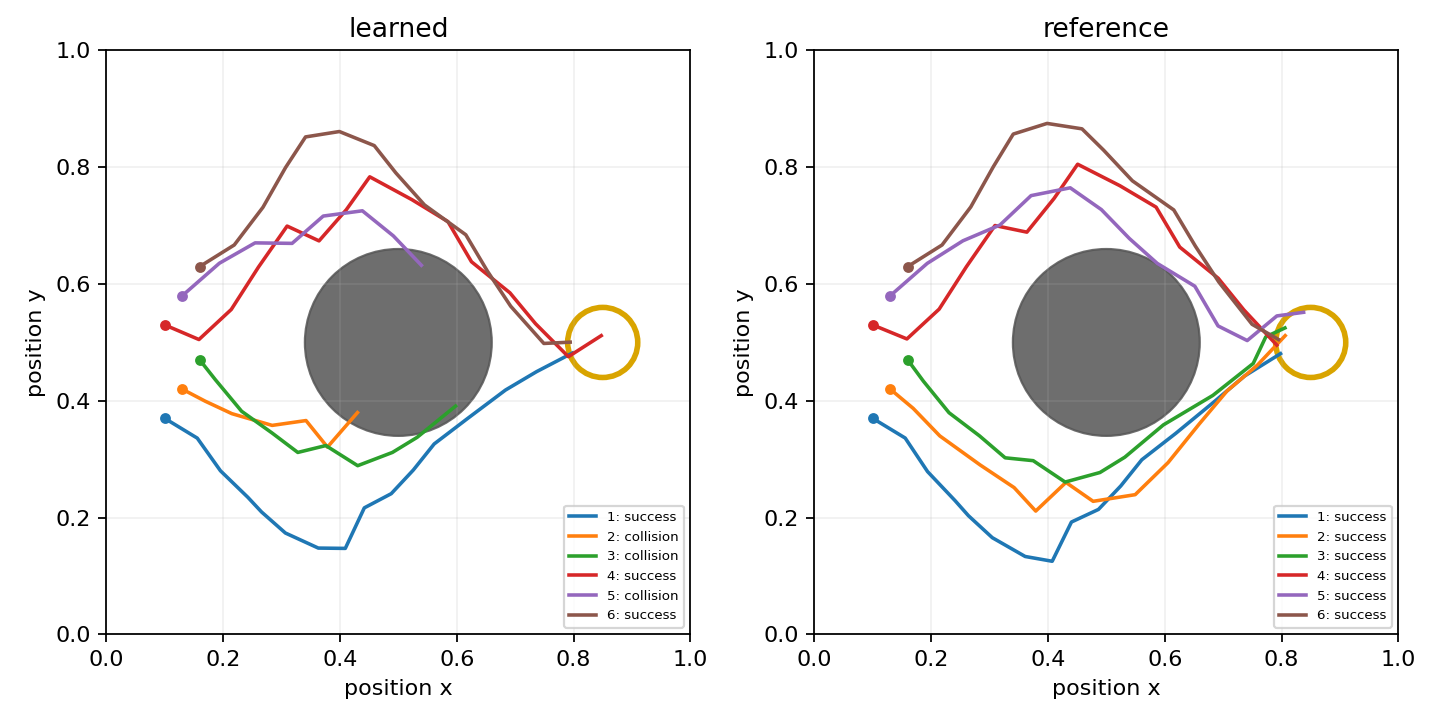

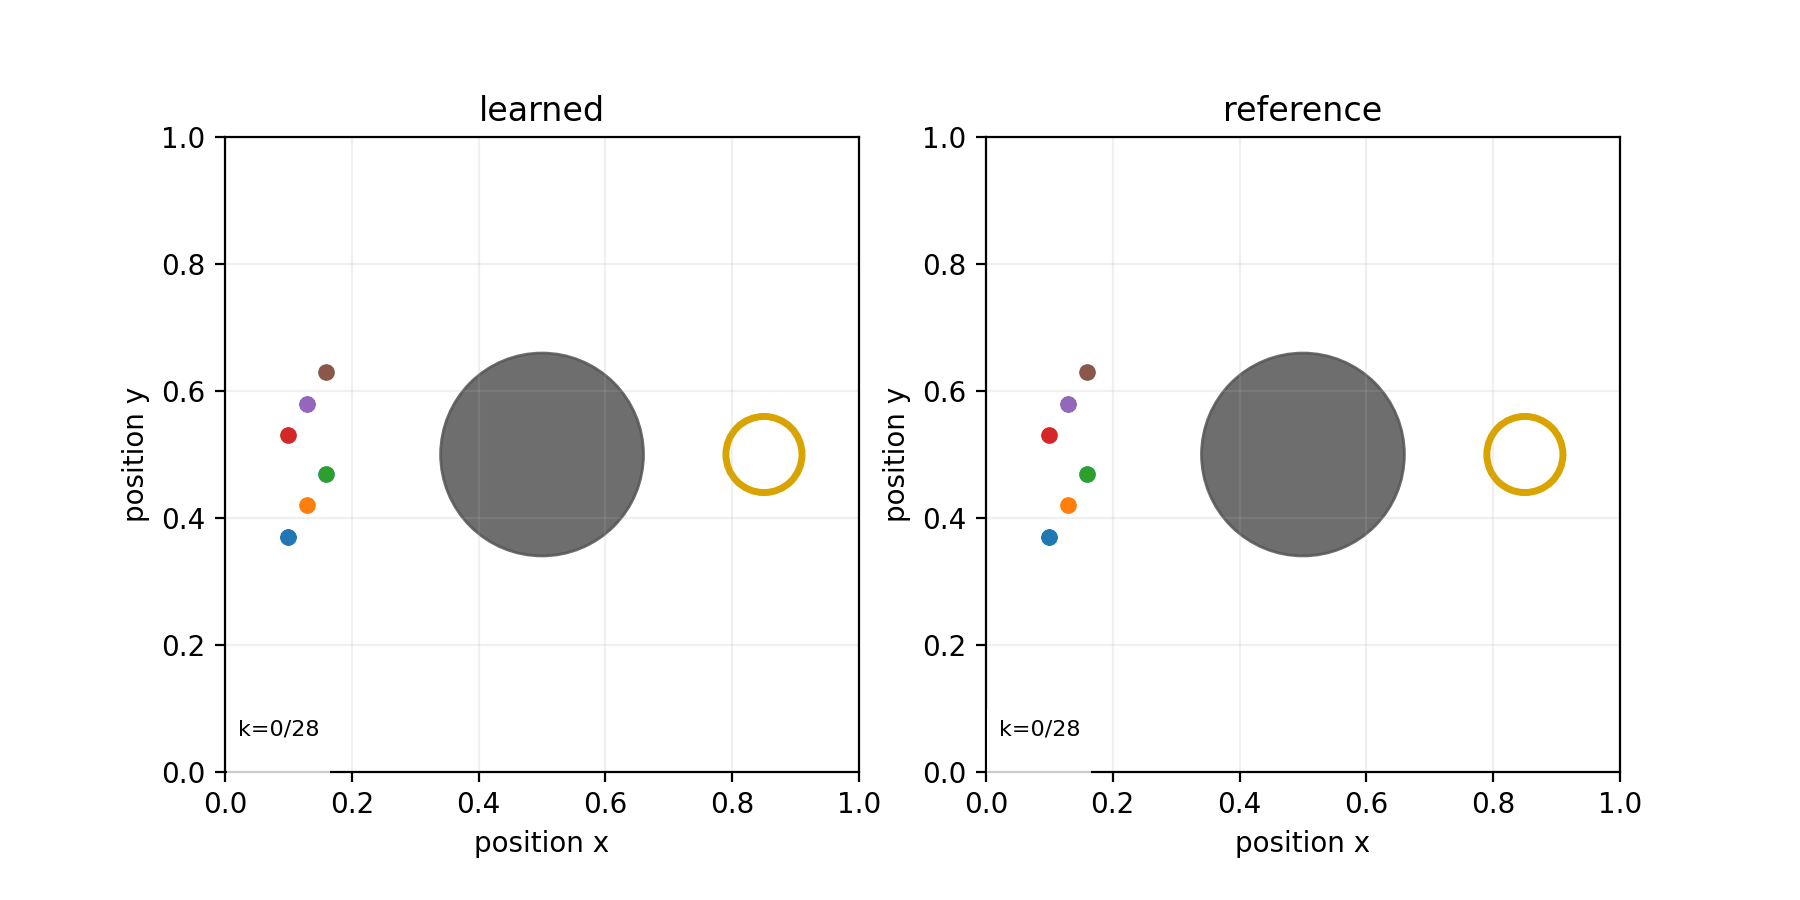

In [3]:
_notebook_output=notebook_run()
if _notebook_output is not None:
    from IPython.display import display, Image
    display(Image(filename=str(_notebook_output/'showcase-trajectories.png')))
    display(Image(filename=str(_notebook_output/'showcase.gif')))
else:
    print('Set PAGR_POINT_RUN to an existing unique run directory to display physical trajectories.')

## Equal-update training comparison

Curve evaluation and the larger final evaluation use disjoint noise banks.

In [4]:
def render_curves(output,c):
    curves=pd.read_csv(output/'curves.csv')
    fields=[('success_rate','success rate'),('discounted_return','discounted return'),
            ('collision_rate','collision rate')]
    fig,axes=plt.subplots(1,3,figsize=(12,3.5))
    for ax,(field,label) in zip(axes,fields):
        for method,group in curves.groupby('method'):
            aggregate=group.groupby('N')[field].agg(['mean','std'])
            ax.plot(aggregate.index,aggregate['mean'],marker='o',label=method)
            if len(curves.seed.unique())>1:
                ax.fill_between(aggregate.index,aggregate['mean']-aggregate['std'],
                                aggregate['mean']+aggregate['std'],alpha=.12)
        ax.set(xlabel='Actor optimizer.step count N',ylabel=label)
        ax.grid(alpha=.25)
    axes[0].legend();fig.tight_layout();fig.savefig(output/'learning-curves.png',dpi=160)
    plt.close(fig)

,seed,method,N,success_rate,collision_rate,timeout_rate,discounted_return,mean_success_length,episodes
0,59000,learned,10,0.498047,0.501953,0.0,-0.056047,13.521569,512
1,59000,reference,10,0.615234,0.384766,0.0,0.138529,13.606349,512


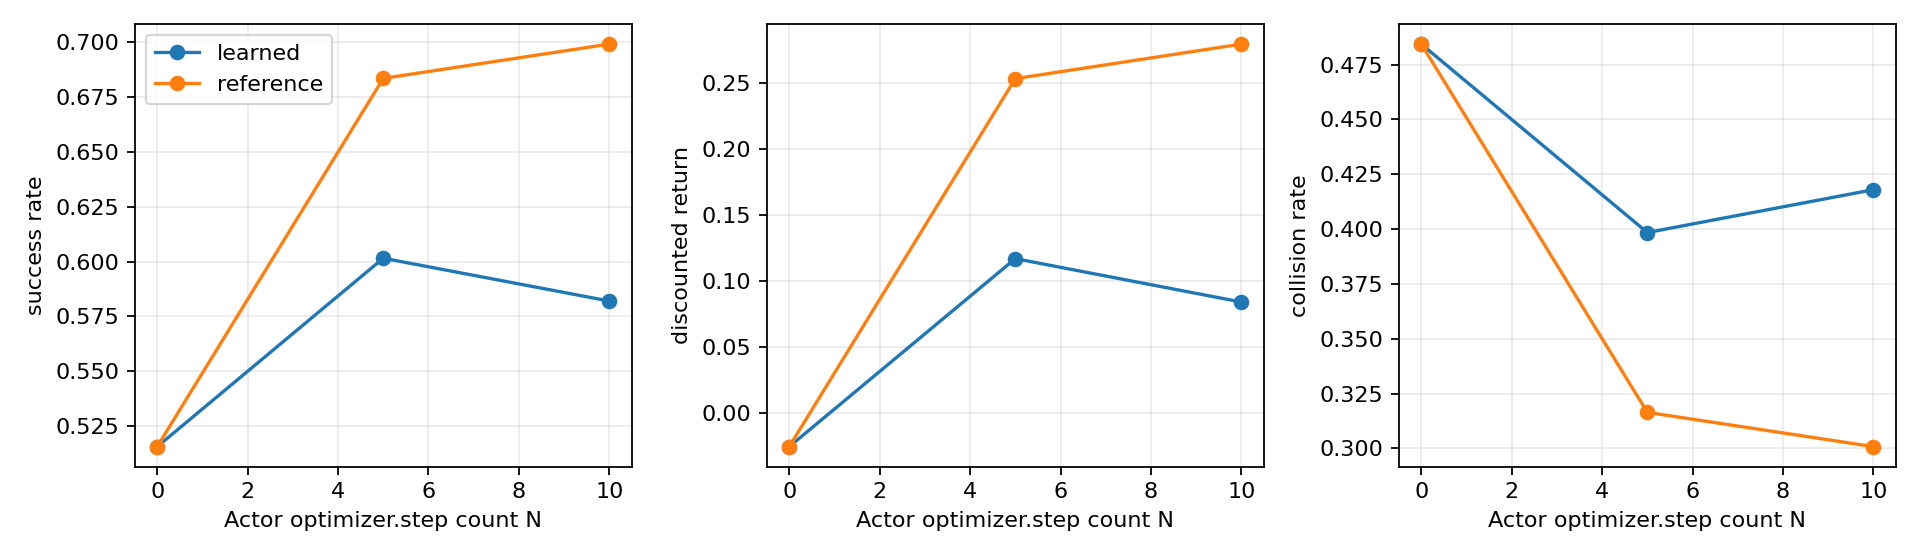

In [5]:
if _notebook_output is not None:
    from IPython.display import display, Image
    display(pd.read_csv(_notebook_output/'final-independent.csv'))
    display(Image(filename=str(_notebook_output/'learning-curves.png')))

## Mechanism audit after the behavioral result

Same ordinary Actor, same generated paths, same Base, same Adam history.
The reference here must pass a separate precision audit before its difference
can be interpreted as actual Critic error. A design smoke is not such proof.

In [6]:
def mechanism_probe(output,c,seed,N):
    sub=output/f'seed-{seed}'
    saved=torch.load(sub/f'learned-N{N}.pt',map_location='cpu',weights_only=True)
    base=load_base(sub/'shared-initialization.pt',c)
    actor=load_actor(sub/f'learned-N{N}.pt',c)
    critic=core.Critic(c);critic.load_state_dict(saved['critic'])
    opt=torch.optim.Adam(actor.parameters(),lr=c.actor_lr)
    opt.load_state_dict(saved['actor_optimizer'])
    task=PointObstacle(c)
    table=PolicyTable(task,actor,base,c.reference_grid,c.reference_policy_samples,
                      c.reference_transition_samples,c.reference_gradient_samples)
    p=torch.tensor(SHOWCASE_START,dtype=torch.float32)
    k=torch.zeros(len(p),dtype=torch.long)
    rng=core.generator(seed_for(seed,880))
    z=torch.randn((len(p),2),generator=rng)
    xi=torch.randn((len(p),c.flow_steps,2),generator=rng)
    paths,_=core.rollout(actor,base,c,k,p,z,xi)
    endpoint=paths[:,-1]
    with torch.enable_grad():
        a=endpoint.detach().requires_grad_(True)
        qhat=critic(k,p,a).mean(-1)
        ghat=torch.autograd.grad(qhat.sum(),a)[0].detach()
    qref,gref_np=table.q_gradient(k.numpy(),p.numpy(),endpoint.numpy())
    gref=torch.from_numpy(gref_np).to(torch.float32)
    al=core.lean_adjoint(base,c,k,p,paths,-c.beta*ghat)
    ar=core.lean_adjoint(base,c,k,p,paths,-c.beta*gref)
    gl,_=core.actor_gradient(actor,base,c,k,p,paths,al)
    gr,_=core.actor_gradient(actor,base,c,k,p,paths,ar)
    dl=core.virtual_adam(actor,opt,gl,c);dr=core.virtual_adam(actor,opt,gr,c)
    adjoint_difference=(ar-al).detach().numpy()
    _,nu,_=core.flow_grid(c)
    label=(nu[None,:,None]*(ar-al)[:,1:]).detach().numpy()
    result=dict(seed=seed,N=N,actor_hash=model_hash(actor),table_actor_hash=table.actor_hash,
                reference_validated=False,points=len(p),
                q_mae=float(np.mean(np.abs(qhat.detach().numpy()-qref))),
                action_gradient_error_rms=float((ghat-gref).square().mean().sqrt()),
                terminal_adjoint_error_rms=float((c.beta*(ghat-gref)).square().mean().sqrt()),
                matching_label_error_rms=float(np.sqrt(np.mean(label**2))),
                actor_parameter_gradient_difference=float((gl-gr).norm()),
                adam_step_difference=float((dl-dr).norm()),
                table_seconds=table.seconds)
    (output/'mechanism-smoke.json').write_text(json.dumps(result,indent=2))
    fig,axes=plt.subplots(1,3,figsize=(10,3))
    axes[0].scatter(qref,qhat.detach().numpy());axes[0].plot([-1,1],[-1,1],'k--',alpha=.4)
    axes[0].set(xlabel='numerical Q',ylabel='critic Q',title='same Actor and (k,p,a)')
    axes[1].quiver(endpoint.numpy()[:,0],endpoint.numpy()[:,1],gref_np[:,0],gref_np[:,1],
                   color='tab:orange',label='numerical')
    axes[1].quiver(endpoint.numpy()[:,0],endpoint.numpy()[:,1],ghat.numpy()[:,0],ghat.numpy()[:,1],
                   color='tab:blue',label='critic')
    axes[1].set(xlabel='action a_x',ylabel='action a_y',title='action-gradient arrows')
    axes[1].legend(fontsize=7)
    axes[2].plot(np.arange(c.flow_steps+1),np.sqrt(np.mean(adjoint_difference**2,axis=(0,2))))
    axes[2].set(xlabel='internal Flow step',ylabel='RMS adjoint difference',title='same Lean recurrence')
    fig.tight_layout();fig.savefig(output/'mechanism-smoke.png',dpi=160);plt.close(fig)
    return result

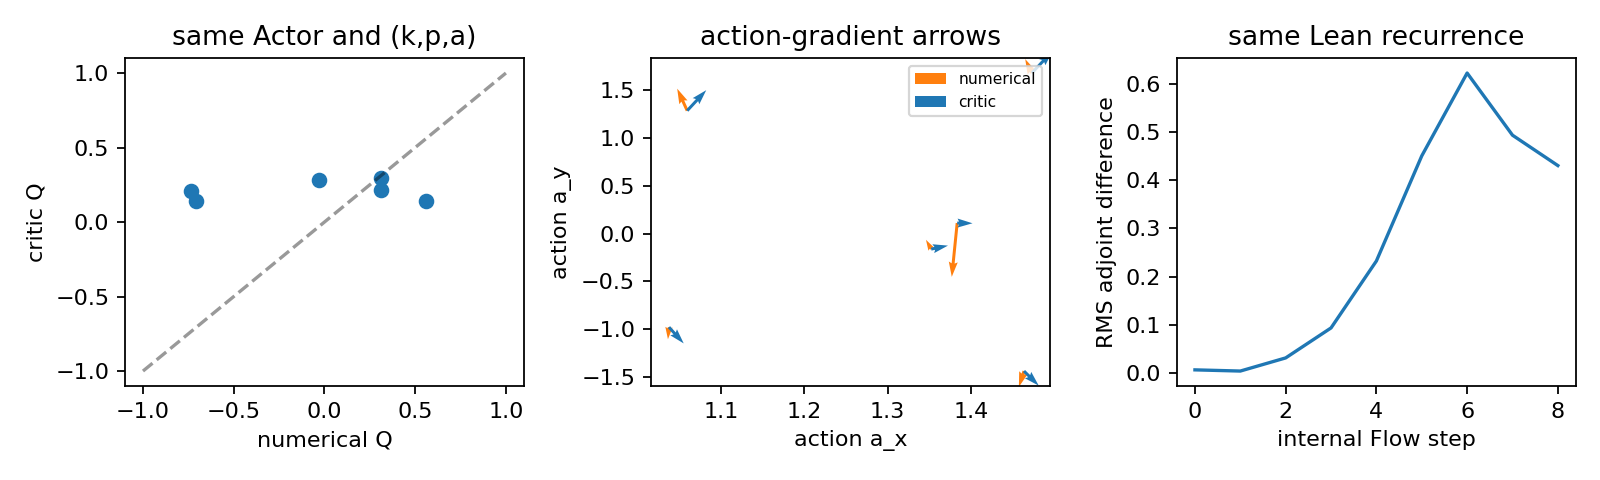

,seed,N,actor_hash,table_actor_hash,reference_validated,points,q_mae,action_gradient_error_rms,terminal_adjoint_error_rms,matching_label_error_rms,actor_parameter_gradient_difference,adam_step_difference,table_seconds
0,59000,10,713a7df4ce353174406b14a3ae743a25127ec2770eaf5e...,713a7df4ce353174406b14a3ae743a25127ec2770eaf5e...,False,6,0.440926,0.107501,0.430006,0.388403,1.522998,0.007358,6.923169


In [7]:
if _notebook_output is not None and (_notebook_output/'mechanism-smoke.json').exists():
    from IPython.display import display, Image
    display(Image(filename=str(_notebook_output/'mechanism-smoke.png')))
    display(pd.DataFrame([json.loads((_notebook_output/'mechanism-smoke.json').read_text())]))


if __name__=='__main__' and '__file__' in globals():
    import argparse
    parser=argparse.ArgumentParser()
    parser.add_argument('--profile',choices=('smoke','formal'),default='smoke')
    args=parser.parse_args()
    c,_=load_config()
    if args.profile=='smoke':
        from dataclasses import replace
        c=replace(c,train_episodes=120,valid_episodes=40,base_updates=20,
                  critic_pretrain_updates=20,actor_updates=2,curve_updates=(0,1,2),
                  curve_episodes=16,final_episodes=32,reference_grid=15,
                  reference_policy_samples=2,reference_transition_samples=8,
                  reference_gradient_samples=32)
        seeds=(59000,)
    else:seeds=c.formal_seeds
    print(run_experiment(c,seeds,args.profile),flush=True)